# 分析有机分子｜SMILES与RDKit

学习如何把有机结构表示转成可复核的分子分析结果，并实际使用`organic-smiles-rdkit` Agent Skill。面向已有基本有机结构知识的学习者；跟随操作为基础，独立解释需要掌握官能团、电荷和立体化学。无需8765、Docker或OpenAI API。

## 本页学什么

用乙醇、乙酸/乙酸根、苯、苯酚、苯甲酸、阿司匹林及明确的立体/盐/同位素教学结构，完成解析、规范表示、描述符、羧酸查询、Morgan指纹和相似度分析。样本含14条记录，其中2条故意无效；它们必须留在错误表，不能静默删除。结构图用RDKit真实绘制，不用生成式图片。

本例不做结构编辑、去盐、中和、互变异构归一或PubChem查询；这些仍属于通用Skill的其他任务范围，不能继承本页验收。

## 必要知识与参考资料

| 知识点 | 在有机化学中的用法 | 具体出处 |
| --- | --- | --- |
| SMILES连接、芳香性、电荷与组分 | 区分苯环、官能团、离子和盐，保留原始结构 | [Daylight SMILES §3.1–3.2](https://www.daylight.com/dayhtml/doc/theory/theory.smiles.html) |
| 同位素与局部立体编码 | 不凭@/@@直接命名R/S；不为未指定中心补构型 | [Daylight §3.3.1–3.3.3](https://www.daylight.com/dayhtml/doc/theory/theory.smiles.html) |
| canonical isomeric SMILES | 同一版本下比较规范表示；不自动合并酸碱、盐和互变异构体 | [RDKit Reading and Writing Molecules](https://www.rdkit.org/docs/GettingStartedInPython.html) |
| SMARTS查询 | 本例`[CX3](=O)[OX2H1]`查找含OH的羧酸片段，不把乙酸根合并为乙酸 | [Daylight SMARTS §4.1–4.3](https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html)；RDKit Substructure Searching |
| 描述符 | MolWt为平均分子量数值（g/mol）；MolLogP是模型估计；TPSA按拓扑规则计算（Å²） | [RDKit Descriptors](https://www.rdkit.org/docs/source/rdkit.Chem.Descriptors.html)；[Crippen MolLogP](https://www.rdkit.org/docs/source/rdkit.Chem.Crippen.html) |
| Morgan bit指纹与Tanimoto | 参数一致时比较结构特征；位碰撞和参数选择影响相似度 | [RDKit Morgan Fingerprints](https://www.rdkit.org/docs/GettingStartedInPython.html#morgan-fingerprints-circular-fingerprints)；[生成器API](https://www.rdkit.org/docs/source/rdkit.Chem.rdFingerprintGenerator.html) |
| Murcko骨架 | 提取算法定义的环系及连接部分；无环分子的空骨架单独标记 | RDKit Getting Started — Murcko Decomposition |

对本页非空位集合，Tanimoto为：

$$T(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

程序同时用RDKit接口和Python位集合独立核算；空并集约定1。该分数不是活性相同概率，也不是严格可计量的“共同化学特征百分比”。

## 数据从哪里来

`molecules.csv`为本项目编写的教学结构集：课程中出现的简单结构，加上用于检验表示、电荷、手性、同位素和错误处理的记录。不是实验数据、临床数据或数据库批量下载。009/010仅标记相反局部手性，不凭符号指定R/S；011/012为故意无效输入。逐记录说明、来源和SHA-256见`data-provenance.json`。

本页使用CCO/OCC演示同一乙醇的两种写法，按SMILES规则核对身份。程序依据官方接口并实测，不把外部说明性数字当作真实结果。官方网页显示版本可能晚于本页固定包，实际运行记录和接口测试才是本例版本依据。知识方法引用与教学输入的取材记录分别标注，详见sources.json与data-provenance.json；代码许可沿用项目现有安排，不擅自新增许可证。

## 运行与参数

在线阅读本Notebook；交互运行时将此.ipynb上传Colab并在自己的账号保存副本。当前仓库私有，不提供未经验证的匿名GitHub下载链接。依赖安装到本次会话独立venv：Python 3.12/3.13兼容、RDKit 2026.3.6、NumPy 2.4.6、Matplotlib 3.11.2；安装失败会停止，记录实际版本。CPU即可，无需GPU。每次最多50条，API最多3轮，每轮60秒，不自动重试；外层230秒停止，终止进程和保存回执另留15秒，不增加科学计算预算。

| 参数 | 默认 | 范围/意义 |
| --- | --- | --- |
| radius | 2 | 1–4整数；修改为3比较局部邻域扩展 |
| fp_size | 2048 | 1024/2048/4096，固定长度bit指纹 |
| include_chirality | true | 指纹和匹配是否使用手性；规范身份始终保留立体信息 |
| query_smarts | `[CX3](=O)[OX2H1]` | 合法且非空的SMARTS；本例查羧酸 |
| reference_id | 005 | 必须是有效记录ID；默认苯 |

调用模板见`task-template.txt`；参数模板见`parameters.json`。Skill原文默认交付代码，本Notebook由用户明确提交执行，使用已审阅的白名单适配器，不执行模型任意生成代码。密钥配置见下方说明及`CONFIGURATION_zh-CN.md`。

## 怎样解释结果

核对analysis.csv的原始字符串、规范表示、分子式、电荷与状态；errors.csv保留无效/空输入，duplicates.csv报告001/002重复映射但不删行。酸与酸根、两种已指定立体结构和13C记录应分别保留。结构图标出ID；相似度图以005为参照。radius=2改3时分子身份、分子式和描述符应不变，相似度可能改变；不要用相似度判定同一性。

结果中的MolLogP、HBD/HBA、TPSA是RDKit方法输出，不是本页测得的溶解度、活性或安全性。SMARTS匹配依赖查询约束，不等于普遍唯一的官能团计数。模型解释单独显示，数值以工具结果为准；模型文字未经专家独立认证。

## 保存与下载材料

本页提供原生Notebook、调用/参数模板、样本、精简源码及运行结果ZIP。运行结果包括输入、参数、环境、CSV、图表、科学检查和脱敏调用回执；下载后以清单复核SHA-256。先运行再保存自己的执行Notebook，未运行的模板没有执行输出。


In [7]:
# @title 1. 环境与内置资源准备（默认折叠）
from pathlib import Path
import base64,hashlib,io,json,os,subprocess,sys,uuid,zipfile
from IPython.display import display,Markdown,Image,HTML
BUNDLE_SHA256 = 'b7f88de6a64e3b3b3760e30cd8884cac343214199716156318e4d250c7a09480'
BUNDLE_B64 = '...'
print('PYTHON_HOST',sys.version)
raw=base64.b64decode(BUNDLE_B64)
if hashlib.sha256(raw).hexdigest()!=BUNDLE_SHA256:raise ValueError('资源ZIP校验失败。')
base=Path('/content') if 'google.colab' in sys.modules else Path.cwd()
workspace=base/('organic-rdkit-'+uuid.uuid4().hex);workspace.mkdir()
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    if z.testzip() is not None or any(Path(n).name!=n for n in z.namelist()):raise ValueError('资源ZIP无效。')
    z.extractall(workspace)
for item in json.loads((workspace/'resource-manifest.json').read_text('utf-8')):
    if hashlib.sha256((workspace/item['file']).read_bytes()).hexdigest()!=item['sha256']:raise ValueError('资源文件哈希不一致。')
subprocess.run([sys.executable,'-m','venv','--without-pip',str(workspace/'.venv')],check=True,capture_output=True,timeout=90)
python=workspace/'.venv'/('Scripts/python.exe' if os.name=='nt' else 'bin/python')
installation=subprocess.run([sys.executable,'-m','pip','--python',str(python),'install','--only-binary=:all:','--retries','0','--timeout','20','--report',str(workspace/'pip-report.json'),'--disable-pip-version-check','-r',str(workspace/'requirements-colab.txt')],text=True,capture_output=True,timeout=180)
(workspace/'pip-install.log').write_text(installation.stdout+'\n'+installation.stderr,encoding='utf-8')
if installation.returncode:raise RuntimeError('依赖安装失败；保留pip日志，不继续计算。')
version_probe=subprocess.run([str(python),'-c','import os;os.environ["MPLBACKEND"]="Agg";import json,platform,rdkit,numpy,matplotlib;print(json.dumps(dict(python=platform.python_version(),rdkit=rdkit.__version__,numpy=numpy.__version__,matplotlib=matplotlib.__version__)))'],capture_output=True,text=True,check=True)
print('PASS资源及安装：',version_probe.stdout.strip())
run_history=[]

pip_check=subprocess.run([sys.executable,'-m','pip','--python',str(python),'check'],capture_output=True,text=True)
(workspace/'pip-check.log').write_text(pip_check.stdout+'\n'+pip_check.stderr,encoding='utf-8')
if pip_check.returncode:raise RuntimeError('独立环境依赖冲突；停止执行。')
print('PASS：独立环境pip check。')


PYTHON_HOST 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PASS资源及安装： {"python": "3.13.16", "rdkit": "2026.03.6", "numpy": "2.4.6", "matplotlib": "3.11.2"}
PASS：独立环境pip check。


## 参数与调用模板

默认查询羧酸，参照物005为苯。先运行默认radius=2，再改为3比较指纹；结构、分子式、电荷和描述符应不变，相似度可能变化。

In [8]:
# @title 2. 修改分析参数
RADIUS = 2 # @param {type:"integer"}
FP_SIZE = 2048 # @param [1024,2048,4096] {type:"raw"}
INCLUDE_CHIRALITY = True # @param {type:"boolean"}
QUERY_SMARTS = "[CX3](=O)[OX2H1]" # @param {type:"string"}
REFERENCE_ID = "005" # @param {type:"string"}
parameters=dict(radius=RADIUS,fp_size=FP_SIZE,include_chirality=INCLUDE_CHIRALITY,query_smarts=QUERY_SMARTS,reference_id=REFERENCE_ID)
print(json.dumps(parameters,ensure_ascii=False))


{"radius": 2, "fp_size": 2048, "include_chirality": true, "query_smarts": "[CX3](=O)[OX2H1]", "reference_id": "005"}


## 配置模型凭据

**本地**：配置文件位置由你自己选择；在参数ENV_FILE指定已有`.env`。只读取其中`DEEPSEEK_API_KEY`，不修改文件，不在代码、命令行或结果里填写密钥值。

**Colab**：左侧钥匙“Secret”中使用同名`DEEPSEEK_API_KEY`并开启当前Notebook访问权限。不要上传整份.env、不要把密钥粘贴到代码。此配置按Google账号及Notebook授权生效；缺失、空值、未授权或API失败会明确停止。新Notebook首次授权需你本人完成。

执行只将内存凭据传给子进程，结束后清除临时变量；调用轨迹不保存Authorization或密钥。只发送本页公开教学结构、Skill指令和本次参数给DeepSeek，不发送个人文件或环境变量集合。


In [ ]:
# @title 3. 仅读取.env或同名Colab Secret（不要填密钥值）
ENV_FILE = "" # 本地填自己的.env路径；Colab保持空白。
import importlib.util
spec=importlib.util.spec_from_file_location('organic_credentials',workspace/'credential_config.py')
credentials=importlib.util.module_from_spec(spec);spec.loader.exec_module(credentials)
globals().pop('model_key',None)
model_key=credentials.load_credential(ENV_FILE)
print('PASS：已读取所选凭据到内存，未显示或保存。')


## 用户提交：真实调用Skill

本单元会将Skill指令、公开教学结构和参数发给DeepSeek，并执行唯一允许的RDKit工具。不会联网查询分子数据库。调用以你运行本单元为提交动作；普通Python示例不冒充Agent验收。

In [ ]:
# @title 4. 提交一次真实Agent与RDKit调用（新输出目录）
run_output=workspace/('run-'+uuid.uuid4().hex)
parameter_file=workspace/('params-'+uuid.uuid4().hex+'.json')
parameter_file.write_text(json.dumps(parameters,ensure_ascii=False,allow_nan=False),encoding='utf-8')
runner=workspace/'runner.py'
runner.write_text("from pathlib import Path\nimport json,os,sys\nfrom skill_agent import run\nrun(Path(__file__).parent,json.loads(Path(sys.argv[1]).read_text('utf-8')),Path(sys.argv[2]),os.environ['DEEPSEEK_API_KEY'],sys.argv[3])\n",encoding='utf-8')
child_env=dict(os.environ);child_env['DEEPSEEK_API_KEY']=model_key;child_env['MPLBACKEND']='Agg'
try:
    proc=subprocess.Popen([str(python),'-B',str(runner),str(parameter_file),str(run_output),'COLAB' if 'google.colab' in sys.modules else 'LOCAL'],env=child_env,stdout=subprocess.PIPE,stderr=subprocess.PIPE,text=True)
    try:stdout,stderr=proc.communicate(timeout=230)
    except subprocess.TimeoutExpired:
        proc.terminate()
        try:proc.communicate(timeout=10)
        except subprocess.TimeoutExpired:proc.kill();proc.communicate(timeout=5)
        raise RuntimeError('执行超时并已终止子进程；本次未验收。') from None
finally:
    child_env.pop('DEEPSEEK_API_KEY',None);globals().pop('model_key',None)
if proc.returncode:
    failure=json.loads((run_output/'failure.json').read_text('utf-8')) if (run_output/'failure.json').exists() else {'message':'初始化失败；检查环境和参数。'}
    raise RuntimeError('真实调用失败：'+failure['message'])
receipt=json.loads((run_output/'run-receipt.json').read_text('utf-8'))
if receipt['status']!='PASS_REAL_MODEL_AND_TOOL_CALL':raise RuntimeError('无合格真实调用回执。')
run_history.append(run_output)
print(json.dumps(receipt,ensure_ascii=False,indent=2))


## 查看结构、相似度和解释

以CSV和numerical-result.json为数值依据。有效/拒绝状态要一起阅读；无环空骨架不表示同一化学家族。

{
  "status": "PASS_BOUNDED_RDKIT_ANALYSIS",
  "records": 14,
  "valid": 12,
  "rejected": 2,
  "duplicates": [
    {
      "id": "002",
      "first_id": "001",
      "rule": "RDKit canonical isomeric SMILES; no standardization"
    }
  ],
  "checks": {
    "record_alignment": true,
    "all_valid_roundtrip": true,
    "finite_descriptors": true,
    "tanimoto_set_oracle": true,
    "self_similarity_one": true,
    "inputs_unchanged": true,
    "ethanol_equivalent": true,
    "acid_and_acetate_distinct": true,
    "enantiomers_preserved": true,
    "invalid_and_empty_retained": true,
    "disconnected_salt_retained": true,
    "isotope_preserved": true,
    "benzene_formula": true,
    "aspirin_formula": true,
    "carboxylic_acid_query": true,
    "ethanol_formula_and_mass": true
  },
  "parameters": {
    "radius": 2,
    "fp_size": 2048,
    "include_chirality": true,
    "query_smarts": "[CX3](=O)[OX2H1]",
    "reference_id": "005"
  },
  "preprocessing": "No desalting, neutraliza

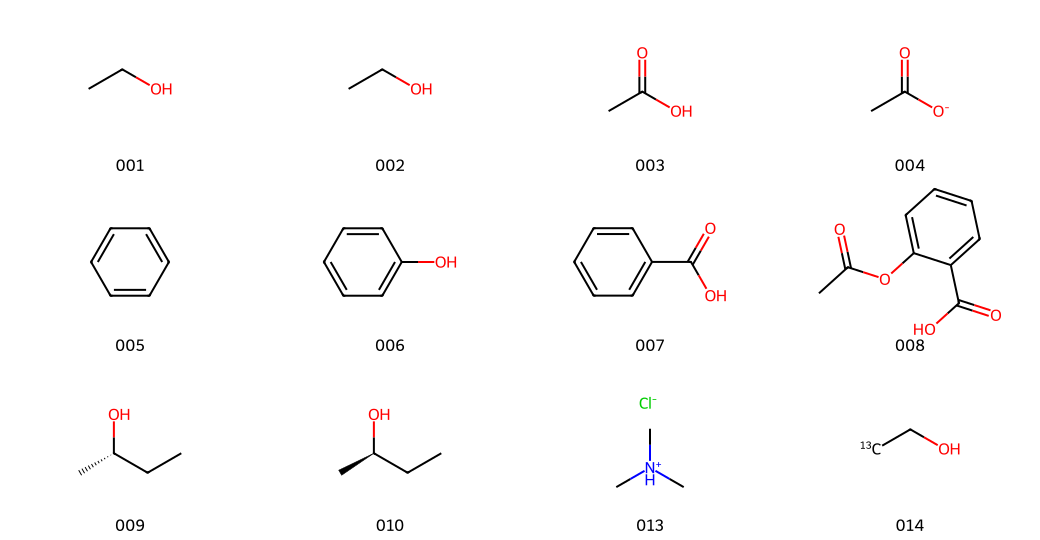

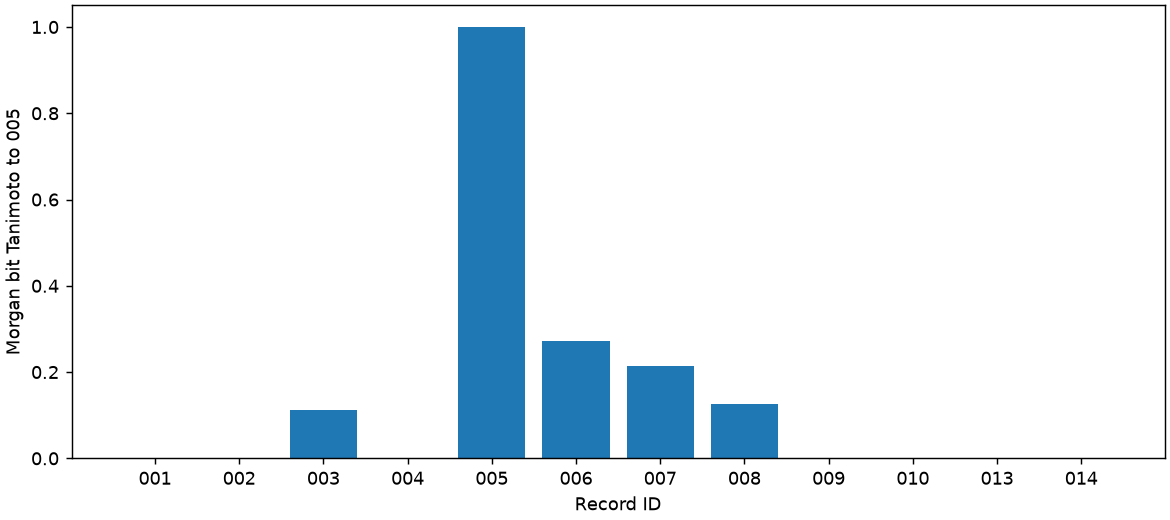

In [11]:
# @title 5. 查看真实结果
numerical=json.loads((run_output/'numerical-result.json').read_text('utf-8'))
print(json.dumps(numerical,ensure_ascii=False,indent=2))
display(Image(filename=str(run_output/'molecules.png')))
display(Image(filename=str(run_output/'similarity.png')))
display(Markdown('### Agent解释（需独立审阅）\n'+(run_output/'agent-explanation.md').read_text('utf-8')))


## 修改参数、保存与下载

修改radius后依次重跑参数、凭据、调用、显示和下载单元；结果保存到新的目录，旧结果保留。课末同时提供本轮和两轮ZIP。用“文件 → 在云端硬盘中保存副本/保存”，再“文件 → 下载 → 下载.ipynb”保存含输出的原生Notebook。不要将含账号、Drive标识或完整调用轨迹的个人验收文件上传GitHub。

In [ ]:
# @title 6. 校验、保存及下载结果
archive=run_output/'organic-smiles-rdkit-results.zip'
with zipfile.ZipFile(archive) as z:
    if z.testzip() is not None:raise ValueError('ZIP损坏。')
    for item in json.loads(z.read('export-manifest.json')):
        if hashlib.sha256(z.read(item['file'])).hexdigest()!=item['sha256']:raise ValueError('结果哈希不一致。')
combined=workspace/'organic-smiles-rdkit-all-runs.zip'
with zipfile.ZipFile(combined,'w',zipfile.ZIP_DEFLATED) as z:
    for i,folder in enumerate(run_history):
        for f in sorted(folder.iterdir()):
            if f.is_file():z.write(f,f'run-{i+1}/'+f.name)
    z.writestr('run-index.json',json.dumps([json.loads((p/'run-receipt.json').read_text('utf-8')) for p in run_history],ensure_ascii=False,indent=2))
for f,label in [(archive,'下载本轮Skill结果ZIP'),(combined,'下载全部运行结果ZIP')]:
    b64=base64.b64encode(f.read_bytes()).decode()
    display(HTML('<a download="'+f.name+'" href="data:application/zip;base64,'+b64+'">'+label+'</a>'))
    print(f.name+' SHA-256: '+hashlib.sha256(f.read_bytes()).hexdigest())
try:
    import ipywidgets as widgets
    from google.colab import files
    button=widgets.Button(description='浏览器下载全部结果ZIP',layout=widgets.Layout(width='250px'))
    button.on_click(lambda _:files.download(str(combined)))
    display(button)
except ImportError:pass
print('PASS：结果ZIP完整性与清单哈希。共'+str(len(run_history))+'次运行；另用文件菜单保存/下载原生Notebook。')


## 自测

1. 为什么CCO与OCC不同字符串仍表示乙醇？
2. 乙酸和乙酸根默认为什么不能合并？
3. @/@@为什么不能直接当R/S？
4. SMARTS羧酸匹配数为何取决于查询式？
5. Morgan半径变化后什么量应保持，什么量可能变化？
6. 为什么相似度1不能证明活性相同？

跟随操作与独立回答分开验收；本页程序验收不能替代专家或教学试学。